/tmp/ipykernel_15891/1230668738.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  orders['is_weekend'] = orders['order_timestamp'].dt.dayofweek >= 5
/tmp/ipykernel_15891/1230668738.py:53: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  restaurant_features.drop(columns=['cancellations'], inplace=True)


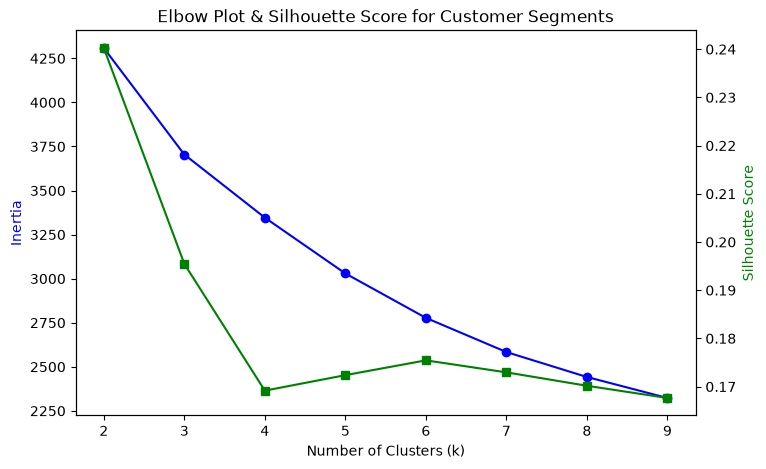

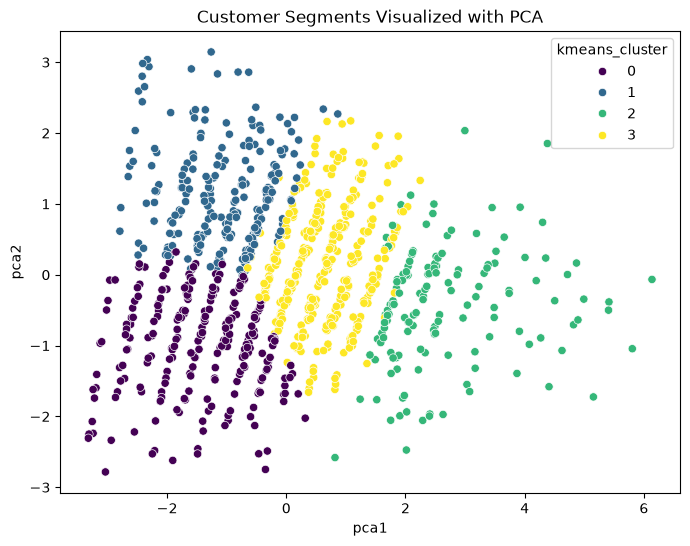

                total_orders  total_spending  average_order_value  \
kmeans_cluster                                                      
0                   3.389961     3285.422741           960.376032   
1                   3.182609     5152.752696          1647.407671   
2                   8.462069    11025.471655          1304.593350   
3                   6.041899     8205.313380          1365.400567   

                weekend_orders  late_night_orders  average_rating_given  \
kmeans_cluster                                                            
0                     1.000000           0.687259              2.854854   
1                     0.673913           0.600000              3.137029   
2                     2.862069           2.703448              2.970962   
3                     1.477654           1.385475              2.984227   

                dbscan_cluster      pca1      pca2  
kmeans_cluster                                      
0                    -0.0077

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. Load Data
# Using ../ to navigate out of the notebooks folder
orders = pd.read_csv('../data/raw/orders.csv')
reviews = pd.read_csv('../data/raw/reviews.csv')
deliveries = pd.read_csv('../data/raw/deliveries.csv')

# 2. Preprocess Time and Status Features in Orders
orders['order_timestamp'] = pd.to_datetime(orders['order_timestamp'])
orders['is_weekend'] = orders['order_timestamp'].dt.dayofweek >= 5
# Defining late-night as 10 PM to 4 AM
orders['is_late_night'] = (orders['order_timestamp'].dt.hour >= 22) | (orders['order_timestamp'].dt.hour < 4)
orders['is_cancelled'] = (orders['order_status'] == 'Cancelled').astype(int)

# 3. Feature Engineering - Customers
cust_orders = orders.groupby('customer_id').agg(
    total_orders=('order_id', 'count'),
    total_spending=('order_amount', 'sum'),
    average_order_value=('order_amount', 'mean'),
    weekend_orders=('is_weekend', 'sum'),
    late_night_orders=('is_late_night', 'sum')
).reset_index()

cust_reviews = reviews.groupby('customer_id').agg(
    average_rating_given=('rating', 'mean')
).reset_index()

# Merge customer metrics and fill nulls (e.g., customers who haven't left a review)
customer_features = pd.merge(cust_orders, cust_reviews, on='customer_id', how='left').fillna(0)

# 4. Feature Engineering - Restaurants
# Merge orders with deliveries (for prep/delivery times) and reviews (for ratings)
rest_merged = orders.merge(deliveries, on='order_id', how='left').merge(reviews[['order_id', 'rating']], on='order_id', how='left')

restaurant_features = rest_merged.groupby('restaurant_id').agg(
    total_orders=('order_id', 'count'),
    revenue=('order_amount', 'sum'),
    average_rating=('rating', 'mean'),
    average_prep_time=('prep_time_min', 'mean'),
    average_delivery_time=('delivery_time_min', 'mean'),
    cancellations=('is_cancelled', 'sum')
).reset_index()

restaurant_features['cancellation_rate'] = restaurant_features['cancellations'] / restaurant_features['total_orders']
restaurant_features.drop(columns=['cancellations'], inplace=True)
restaurant_features = restaurant_features.fillna(0)

# 5. Scaling (Using Customers for segmentation)
X_customers = customer_features.drop(columns=['customer_id'])
scaler = StandardScaler()
X_cust_scaled = scaler.fit_transform(X_customers)

# 6. K-Means: Elbow Method & Silhouette Score
inertia = []
sil_scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cust_scaled)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_cust_scaled, kmeans.labels_))

# Plot Elbow and Silhouette
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(K_range, inertia, marker='o', color='blue', label='Inertia')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color='blue')

ax2 = ax1.twinx()
ax2.plot(K_range, sil_scores, marker='s', color='green', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='green')
plt.title('Elbow Plot & Silhouette Score for Customer Segments')
plt.show()

# Fit optimal K-Means (Modify 'optimal_k' based on your elbow plot results)
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
customer_features['kmeans_cluster'] = kmeans_final.fit_predict(X_cust_scaled)

# 7. DBSCAN Implementation
dbscan = DBSCAN(eps=1.5, min_samples=5)
customer_features['dbscan_cluster'] = dbscan.fit_predict(X_cust_scaled)

# 8. PCA Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cust_scaled)
customer_features['pca1'] = X_pca[:, 0]
customer_features['pca2'] = X_pca[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(x='pca1', y='pca2', hue='kmeans_cluster', data=customer_features, palette='viridis')
plt.title('Customer Segments Visualized with PCA')
plt.show()

# 9. Cluster Profiling & Business Names
cluster_profiles = customer_features.groupby('kmeans_cluster').mean(numeric_only=True)
print(cluster_profiles)

## Cluster 2: Premium Frequent Night-Owls

Why: This segment has the highest total spending (₹11,025), highest total orders (8.4), and highest average order value (₹1,304). They dominate weekend orders (2.8) and late-night orders (2.7).

## Cluster 3: High-Value Regulars

Why: The second-highest spending group (₹8,205) with strong ordering frequency (6 orders). They have a balanced mix of weekend and late-night ordering.

## Cluster 1: Occasional High-Spenders

Why: They order less frequently (3.1 orders) but have the highest average order value (₹1,647). They rarely order late at night and give the highest average ratings (3.13).

## Cluster 0: Budget / Occasional Users

Why: The lowest total spending (₹3,285) with low average order value (₹960) and infrequent ordering (3.3 orders). They also give the lowest ratings (2.85).